# RQ2 — Cross-Platform Sentiment Comparison: Mastodon vs BlueSky

**Author**: Xianglong Fu, Wen Zhuo, Muchuan Ji, Chang Gu, Zeming Ji
**Date**: May 2026  
**Team**: COMP90024 Team 47

---

## Research Question

> **RQ2**: How do users on Mastodon and BlueSky differ in their 
> sentiment expression and discourse patterns within the Australian 
> social-media context?

This notebook addresses RQ2 through four complementary lenses:

1. **Vocabulary** — what words dominate each platform's discourse? 
   (word clouds)
2. **Temporal sentiment** — does the daily sentiment distribution 
   shift over time on each platform? (weekly violin plots)
3. **Temperature × sentiment** — is the temperature–sentiment 
   relationship similar across platforms?
4. **Precipitation × sentiment** — does rainfall affect platforms 
   differently?

## Data scope

- **Mastodon**: ~15,000 posts (full corpus, no city filter)
- **BlueSky**: ~14,500 posts (after weather-keyword bias filter)
- **Weather**: 1,492 daily observations, 4 Australian cities
- **Time window**: 2026-01-26 → 2026-05-14 (~3.5 months)

For temperature/precipitation analyses, weather is averaged across 
the four target cities to provide a representative Australian baseline.

## Tooling

- **Data layer**: `frontend/data_loader.py` (centralized ES access)
- **Visualization**: Plotly for interactive figures, exported to PNG 
  for the report
- **Text processing**: NLTK + wordcloud
- **Statistical**: SciPy (KS test, Mann–Whitney U, Spearman)

## Prerequisites

```bash
# Elasticsearch must be reachable on localhost:9200
kubectl port-forward service/elasticsearch-es-http -n elastic 9200:9200

# Python packages (auto-checked by cell 2)
pip install elasticsearch pandas numpy plotly wordcloud kaleido nltk scipy
```

In [1]:
"""Imports & path setup."""

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Plotly
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# WordCloud + NLTK
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords

# SciPy
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# Ensure data_loader.py is importable (notebook is in frontend/)
NB_DIR = Path.cwd()
if NB_DIR.name == "frontend":
    sys.path.insert(0, str(NB_DIR))
else:
    sys.path.insert(0, str(NB_DIR / "frontend"))

import data_loader as dl

# Download NLTK stopwords once
try:
    stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)

# Figure output directory (for report)
FIG_DIR = Path("../docs/figures") if NB_DIR.name == "frontend" else Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig_plotly(fig: go.Figure, name: str, width: int = 1200, height: int = 600):
    """Save a Plotly figure as both PNG (for report) and HTML (for interactive)."""
    fig.write_image(FIG_DIR / f"{name}.png", width=width, height=height, scale=2)
    fig.write_html(FIG_DIR / f"{name}.html")
    print(f"  → saved {name}.png + {name}.html")


print("✓ Imports done.")
print(f"  Notebook dir: {NB_DIR}")
print(f"  Figure dir:   {FIG_DIR.resolve()}")

/Users/fuxianglong/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


✓ Imports done.
  Notebook dir: /Users/fuxianglong/Desktop/comp90024_team_47/frontend
  Figure dir:   /Users/fuxianglong/Desktop/comp90024_team_47/docs/figures


## 0.1 Load data

We load Mastodon, BlueSky, and weather via `data_loader.py`. This may 
take 30–60 seconds (paginated ES fetches). The `data_loader` module 
applies the BlueSky weather-bias filter automatically.

In [2]:
"""Load data from Elasticsearch."""

# Inventory first
print("Data inventory:")
inv = dl.get_overview()
for k, v in inv.items():
    print(f"  {k:18s}  {v:>8,}")
print()

# Load all posts (no city filter - RQ2 is platform-level)
print("Loading Mastodon (full corpus)...")
mastodon_df = dl.load_posts("mastodon", cities_only=False)
print(f"  ✓ {len(mastodon_df):,} posts")

print("Loading BlueSky (clean filter applied)...")
bluesky_df = dl.load_posts("bluesky", cities_only=False)
print(f"  ✓ {len(bluesky_df):,} posts")

print("Loading weather (4 target cities)...")
weather_df = dl.load_weather(cities_only=True)
print(f"  ✓ {len(weather_df):,} records")

# Combined for cross-platform analysis
posts_df = pd.concat([mastodon_df, bluesky_df], ignore_index=True)
print(f"\nCombined posts: {len(posts_df):,}")
print(f"  Mastodon: {(posts_df['platform'] == 'Mastodon').sum():,}")
print(f"  BlueSky:  {(posts_df['platform'] == 'BlueSky').sum():,}")
print(f"  Date range: {posts_df['date'].min().date()} → {posts_df['date'].max().date()}")

Data inventory:
✓ Connected to Elasticsearch 9.2.4
  mastodon_total        15,145
  bluesky_total         15,375
  bluesky_clean         14,551
  weather_total          1,492

Loading Mastodon (full corpus)...
  ✓ 15,145 posts
Loading BlueSky (clean filter applied)...
  ✓ 14,551 posts
Loading weather (4 target cities)...
  ✓ 1,492 records

Combined posts: 29,696
  Mastodon: 15,145
  BlueSky:  14,551
  Date range: 2026-01-26 → 2026-05-14


---

# Part 1 — Vocabulary Comparison via Word Clouds

The most direct read on platform discourse is the words themselves. 
We construct word clouds for each platform's posts, after removing 
URLs, mentions, hashtags, English stopwords, and platform-specific 
noise (e.g. "rt", "via", "amp").

## Method

1. Concatenate `content_clean` text per platform.
2. Strip URLs, @mentions, #hashtags, and ASCII punctuation.
3. Tokenize and lowercase.
4. Remove NLTK English stopwords + custom stopword list 
   (`twitter`/`bluesky`/`mastodon`-specific noise).
5. Generate word cloud with consistent styling per platform.

Word size is proportional to frequency. Color encodes platform 
identity (blue = Mastodon, orange = BlueSky) for consistency with 
later figures.

In [16]:
"""Text preprocessing for word clouds."""

import re

EN_STOPWORDS = set(stopwords.words("english"))

# Custom stopwords — common social-media noise + project-specific terms
CUSTOM_STOPWORDS = {
    # Social media noise
    "rt", "via", "amp", "https", "http", "www", "com", "org",
    "co", "html", "htm", "twitter", "bluesky", "mastodon", "fediverse",
    
    # Generic verbs/words
    "said", "says", "say", "saying", "get", "got", "getting", "go", "going",
    "make", "made", "making", "would", "could", "should", "one", "two",
    "thing", "things", "way", "people", "person", "time", "year", "years",
    "today", "now", "really", "much", "many", "also", "even", "still",
    "well", "back", "see", "seen", "know", "knows", "like", "good", "great",
    "post", "posts", "posted", "thread", "feed",
    
    # NEW: Geographic terms (acquisition artifacts — we explicitly 
    # searched for these, so their prevalence reflects our query, not 
    # organic discourse)
    "australia", "australian", "australians", "oz", "aussie", "aussies",
    "sydney", "melbourne", "brisbane", "perth", "adelaide", 
    "canberra", "hobart", "darwin", "nsw", "vic", "qld", "wa", "sa", "tas", "act", "nt",
    "nation",
    
    # NEW: Australian political hashtags (also acquisition artifacts)
    "auspol", "ausvotes", "auspol2026",
    
    # NEW: BlueSky/Mastodon platform self-references
    "bsky", "atproto", "fediverse",
    
    # NEW: Bot/RSS/automation noise
    "newsbeep",      # Mastodon news bot account
    "dlvr",          # dlvr.it — RSS-to-social tool
    "byteseu",       # RSS aggregator
    "ifttt",         # automation service
    "buffer",        # social media scheduler
    "hootsuite",
    "rss",

    # NEW: 通用时间词 + 新闻骨架词
    "new", "news", "first", "last", "day", "days", "week", "weeks", 
    "month", "months", "year", "year", "may", "work", "need",
    "today", "yesterday", "tomorrow", "morning", "night", 
    "available", "items", "saved", "right",
    
    # NEW: Mastodon 平台 specific bots/hashtags
    "politicalgadgets", "railnews",
    
    # NEW: 通用 social media noise
    "facebook", "instagram", "tiktok", "youtube",
}
ALL_STOPWORDS = EN_STOPWORDS | CUSTOM_STOPWORDS


def preprocess_text(text: str) -> str:
    """Clean a single post for word-cloud generation."""
    if not isinstance(text, str):
        return ""
    
    # Strip URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    # Strip @mentions and #hashtags (we want plain vocabulary)
    text = re.sub(r"[@#]\w+", " ", text)
    # Strip punctuation and digits
    text = re.sub(r"[^\w\s]|[\d]", " ", text)
    # Collapse whitespace, lowercase
    text = re.sub(r"\s+", " ", text).strip().lower()
    
    # Tokenize and drop stopwords + 1-2 char tokens
    tokens = [t for t in text.split() 
              if t not in ALL_STOPWORDS and len(t) >= 3]
    return " ".join(tokens)


# Build per-platform corpora
print("Preprocessing text...")
mastodon_text = " ".join(
    preprocess_text(t) for t in mastodon_df["content_clean"].dropna()
)
bluesky_text = " ".join(
    preprocess_text(t) for t in bluesky_df["content_clean"].dropna()
)

print(f"  Mastodon corpus: {len(mastodon_text.split()):,} tokens")
print(f"  BlueSky  corpus: {len(bluesky_text.split()):,} tokens")

Preprocessing text...
  Mastodon corpus: 289,713 tokens
  BlueSky  corpus: 181,461 tokens


  → saved rq2_fig1_wordclouds.png


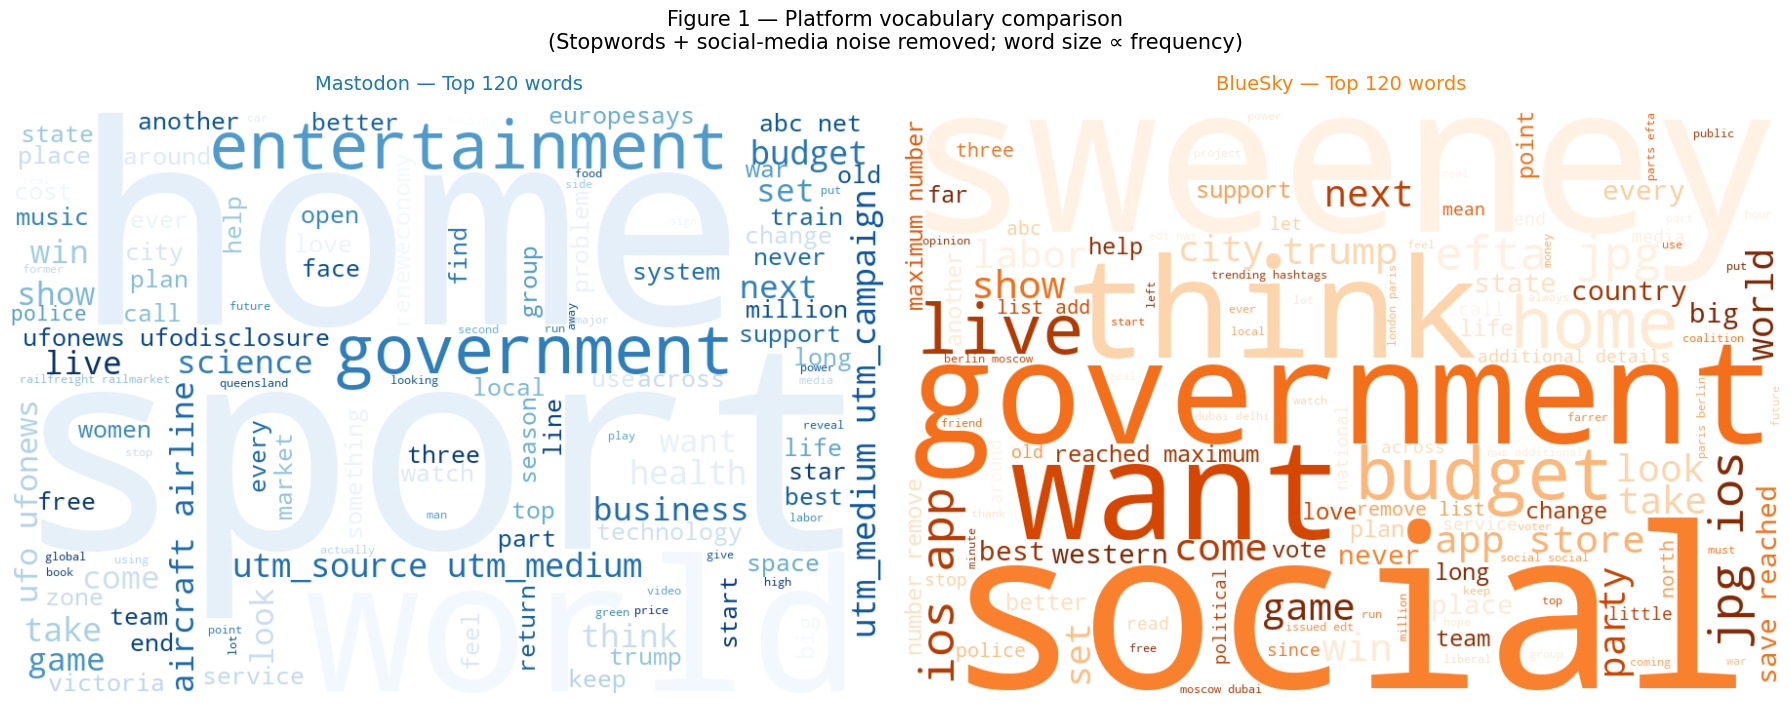


=== Top 20 words on each platform ===

Mastodon             BlueSky             
----------------------------------------
  sports         1506    social          751
  entertainment   667    sweeney         521
  business        642    south           440
  health          637    budget          437
  aircraft        589    trump           415
  world           531    government      371
  footscray       521    tax             322
  science         484    party           309
  government      465    labor           308
  music           430    world           307
  technology      425    live            298
  space           413    app             291
  home            400    city            285
  big             397    media           282
  airlines        388    think           269
  budget          387    euphoria        261
  gas             362    store           258
  utm_source      358    game            256
  utm_medium      355    jpg             251
  tax             347 

In [17]:
"""Figure 1 — Word clouds, Mastodon vs BlueSky."""

import matplotlib.pyplot as plt

# Generate two word clouds with platform-appropriate colors
wc_mastodon = WordCloud(
    width=900, height=600,
    background_color="white",
    max_words=120,
    colormap="Blues",
    relative_scaling=0.5,
    min_font_size=10,
    random_state=42,
    stopwords=ALL_STOPWORDS,
).generate(mastodon_text)

wc_bluesky = WordCloud(
    width=900, height=600,
    background_color="white",
    max_words=120,
    colormap="Oranges",
    relative_scaling=0.5,
    min_font_size=10,
    random_state=42,
    stopwords=ALL_STOPWORDS,
).generate(bluesky_text)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].imshow(wc_mastodon, interpolation="bilinear")
axes[0].set_title("Mastodon — Top 120 words", fontsize=14, color=dl.COLORS["Mastodon"], pad=15)
axes[0].axis("off")

axes[1].imshow(wc_bluesky, interpolation="bilinear")
axes[1].set_title("BlueSky — Top 120 words", fontsize=14, color=dl.COLORS["BlueSky"], pad=15)
axes[1].axis("off")

plt.suptitle("Figure 1 — Platform vocabulary comparison\n"
             "(Stopwords + social-media noise removed; word size ∝ frequency)",
             fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "rq2_fig1_wordclouds.png", dpi=150, bbox_inches="tight", facecolor="white")
print(f"  → saved rq2_fig1_wordclouds.png")
plt.show()

# Top 20 words per platform (numeric backup)
print("\n=== Top 20 words on each platform ===")
print(f"\n{'Mastodon':<20s} {'BlueSky':<20s}")
print("-" * 40)
m_top = pd.Series(mastodon_text.split()).value_counts().head(20)
b_top = pd.Series(bluesky_text.split()).value_counts().head(20)
for (mw, mc), (bw, bc) in zip(m_top.items(), b_top.items()):
    print(f"  {mw:<14s} {mc:>4d}    {bw:<14s} {bc:>4d}")

---

# Part 2 — Temporal Sentiment Distribution by Platform

How does each platform's sentiment distribution evolve over time? We 
plot the **daily empirical distribution** of `sentiment_compound` 
scores as box plots (one box per day) for each platform separately.


## Method

1. For each platform, group posts by `date` field (yyyy-MM-dd).
2. Drop days with fewer than 10 posts.
3. Distribution per day; overlay mean line; shade IQR band.

In [36]:
"""Prepare daily-level data per platform for time-series plotting."""

def prepare_daily(df: pd.DataFrame, 
                  min_posts: int = 10,
                  start_date: str = "2026-04-05") -> pd.DataFrame:
    """Group posts by date, filter for analysis window.
    
    Args:
        df: posts DataFrame
        min_posts: minimum posts/day to retain
        start_date: drop days before this (yyyy-MM-dd)
    """
    df = df.copy()
    df["day"] = pd.to_datetime(df["date"]).dt.normalize()
    
    # Filter by start date (align Mastodon/BlueSky time windows)
    start = pd.to_datetime(start_date)
    df = df[df["day"] >= start]
    
    # Count posts per day; drop sparse days
    day_counts = df.groupby("day").size()
    valid_days = day_counts[day_counts >= min_posts].index
    
    print(f"  Total days (≥ {start_date}): {len(day_counts)}")
    print(f"  Days with ≥{min_posts} posts:    {len(valid_days)}")
    print(f"  Posts kept:                      {df['day'].isin(valid_days).sum():,} "
          f"({df['day'].isin(valid_days).mean():.1%})")
    
    return df[df["day"].isin(valid_days)][["day", "sentiment_compound"]].dropna()

# Add at end of Cell 9:

# Prepare daily weather (averaged across 4 cities) — used in Figures 2 & 3
print("\nPreparing daily weather (4-city average)...")

# Average weather variables across 4 cities per day
numeric_cols = weather_df.select_dtypes(include="number").columns.tolist()
weather_daily = (weather_df.groupby("date")[numeric_cols]
                           .mean().reset_index())
weather_daily["day"] = weather_daily["date"]

# Find the temperature field (handles different mapping names)
TEMP_FIELD = dl.find_field(weather_daily, "temp", "mean") \
          or dl.find_field(weather_daily, "temperature", "mean") \
          or dl.find_field(weather_daily, "temp")

print(f"  Using temperature field: {TEMP_FIELD}")
print(f"  Date range: {weather_daily['day'].min().date()} → {weather_daily['day'].max().date()}")
print(f"  Temperature mean across all days: {weather_daily[TEMP_FIELD].mean():.1f}°C")


print("Preparing Mastodon daily data...")
m_daily = prepare_daily(mastodon_df, min_posts=10)
print()

print("Preparing BlueSky daily data...")
b_daily = prepare_daily(bluesky_df, min_posts=10)

# Helper for computing daily stats
def daily_stats(df: pd.DataFrame) -> pd.DataFrame:
    """Per-day mean, median, IQR for sentiment_compound."""
    return df.groupby("day")["sentiment_compound"].agg(
        mean="mean", 
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        n="count",
    ).reset_index()


m_stats = daily_stats(m_daily)
b_stats = daily_stats(b_daily)

print(f"\nMastodon: {len(m_stats)} valid days")
print(f"  Date range: {m_stats['day'].min().date()} → {m_stats['day'].max().date()}")
print(f"  Mean of daily means: {m_stats['mean'].mean():.3f}")
print(f"\nBlueSky: {len(b_stats)} valid days")
print(f"  Date range: {b_stats['day'].min().date()} → {b_stats['day'].max().date()}")
print(f"  Mean of daily means: {b_stats['mean'].mean():.3f}")

# 查找降雨字段
PRECIP_FIELD = dl.find_field(weather_daily, "precip", "sum") \
            or dl.find_field(weather_daily, "precipitation", "sum") \
            or dl.find_field(weather_daily, "precip") \
            or dl.find_field(weather_daily, "rain")

print(f"  Using precipitation field: {PRECIP_FIELD}")
if PRECIP_FIELD:
    print(f"  Precip range: {weather_daily[PRECIP_FIELD].min():.1f} - "
          f"{weather_daily[PRECIP_FIELD].max():.1f} mm")


Preparing daily weather (4-city average)...
  Using temperature field: temp_mean
  Date range: 2025-05-01 → 2026-05-13
  Temperature mean across all days: 17.9°C
Preparing Mastodon daily data...
  Total days (≥ 2026-04-05): 40
  Days with ≥10 posts:    40
  Posts kept:                      13,433 (100.0%)

Preparing BlueSky daily data...
  Total days (≥ 2026-04-05): 40
  Days with ≥10 posts:    39
  Posts kept:                      14,074 (100.0%)

Mastodon: 40 valid days
  Date range: 2026-04-05 → 2026-05-14
  Mean of daily means: 0.120

BlueSky: 39 valid days
  Date range: 2026-04-06 → 2026-05-14
  Mean of daily means: 0.031
  Using precipitation field: precipitation_mm
  Precip range: 0.0 - 22.5 mm


In [34]:
def daily_ribbon_figure(daily_df: pd.DataFrame, 
                       platform_name: str,
                       color: str,
                       fig_num: int,
                       weather_daily: pd.DataFrame = None,
                       temp_field: str = None) -> go.Figure:
    """Daily sentiment over time: ribbon + optional temperature overlay.
    
    Args:
        daily_df: per-post (day, sentiment_compound)
        platform_name: e.g. "Mastodon"
        color: platform color hex
        fig_num: figure number for title
        weather_daily: optional weather DataFrame with (day, temp) columns
        temp_field: column name in weather_daily for temperature
    """
    # Compute daily stats
    stats = daily_df.groupby("day")["sentiment_compound"].agg(
        mean="mean", median="median",
        q10=lambda x: x.quantile(0.10),
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        q90=lambda x: x.quantile(0.90),
        n="count",
    ).reset_index().sort_values("day")
    
    r, g, b = int(color[1:3], 16), int(color[3:5], 16), int(color[5:7], 16)
    
    fig = go.Figure()
    
    # === Temperature line (right axis, in background) ===
    if weather_daily is not None and temp_field is not None:
        # Filter weather to the same date range as sentiment data
        date_min = stats["day"].min()
        date_max = stats["day"].max()
        wx = weather_daily[(weather_daily["day"] >= date_min) & 
                          (weather_daily["day"] <= date_max)].sort_values("day")
        
        fig.add_trace(go.Scatter(
            x=wx["day"], y=wx[temp_field],
            mode="lines",
            line=dict(color="#d62728", width=2, dash="solid"),  # red
            name="Daily mean temperature (°C)",
            yaxis="y2",
            opacity=0.7,
            hovertemplate="<b>%{x|%Y-%m-%d}</b><br>"
                          "Temperature: %{y:.1f}°C<extra></extra>",
        ))
    
    # === Sentiment elements (left axis) ===
    
    # Outer band: 10–90 percentile
    fig.add_trace(go.Scatter(
        x=list(stats["day"]) + list(stats["day"][::-1]),
        y=list(stats["q90"]) + list(stats["q10"][::-1]),
        fill="toself",
        fillcolor=f"rgba({r}, {g}, {b}, 0.10)",
        line=dict(color="rgba(0,0,0,0)"),
        name="10–90 percentile",
        hoverinfo="skip",
    ))
    
    # IQR band: 25–75
    fig.add_trace(go.Scatter(
        x=list(stats["day"]) + list(stats["day"][::-1]),
        y=list(stats["q75"]) + list(stats["q25"][::-1]),
        fill="toself",
        fillcolor=f"rgba({r}, {g}, {b}, 0.25)",
        line=dict(color="rgba(0,0,0,0)"),
        name="25–75 percentile (IQR)",
        hoverinfo="skip",
    ))
    
    # Median (dotted)
    fig.add_trace(go.Scatter(
        x=stats["day"], y=stats["median"],
        mode="lines",
        line=dict(color=color, width=1, dash="dot"),
        name="Daily median",
        hovertemplate="<b>%{x|%Y-%m-%d}</b><br>"
                      "Median: %{y:.3f}<extra></extra>",
    ))
    
    # Mean line (primary)
    fig.add_trace(go.Scatter(
        x=stats["day"], y=stats["mean"],
        mode="lines+markers",
        line=dict(color=color, width=2.8),
        marker=dict(size=5, color=color, line=dict(color="white", width=0.5)),
        name="Daily mean sentiment",
        hovertemplate="<b>%{x|%Y-%m-%d}</b><br>"
                      "Mean: %{y:.3f}<br>"
                      "Posts: %{customdata}<extra></extra>",
        customdata=stats["n"],
    ))
    
    # Zero line (sentiment)
    fig.add_hline(y=0, line_dash="dash", line_color="gray",
                  opacity=0.5)
    
    # Dynamic Y range
    y_lo = min(stats["q10"].min(), -0.05) - 0.1
    y_hi = max(stats["q90"].max(),  0.05) + 0.1
    y_lo = max(y_lo, -1.0)
    y_hi = min(y_hi,  1.0)
    
    # Layout: dual Y axis
    has_weather = weather_daily is not None and temp_field is not None
    
    fig.update_layout(
        title=dict(
            text=f"<b>Figure {fig_num} — {platform_name}: Daily sentiment + temperature over time</b><br>"
                 f"<sub>Sentiment (colored): mean line + IQR + 10–90 percentile bands"
                 f"{' | Temperature (red): 4-city daily mean' if has_weather else ''}</sub>",
            x=0.02, font=dict(size=14),
        ),
        xaxis_title="Date",
        yaxis=dict(
            title="VADER compound sentiment score",
            range=[y_lo, y_hi],
            side="left",
            color=color,
        ),
        yaxis2=dict(
            title="Temperature (°C)",
            overlaying="y",
            side="right",
            color="#d62728",
            showgrid=False,
            range=[0, 30]
        ) if has_weather else dict(),
        template="plotly_white",
        height=620,
        margin=dict(t=150, b=60, l=70, r=70), 
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
        hovermode="x unified",
    )
    return fig


# === Re-render Figure 2 (Mastodon) with temperature overlay ===
fig2 = daily_ribbon_figure(
    m_daily,
    platform_name="Mastodon",
    color=dl.COLORS["Mastodon"],
    fig_num=2,
    weather_daily=weather_daily,
    temp_field=TEMP_FIELD,
)
fig2.show()
save_fig_plotly(fig2, "rq2_fig2_mastodon_daily_sentiment")

  → saved rq2_fig2_mastodon_daily_sentiment.png + rq2_fig2_mastodon_daily_sentiment.html


In [35]:
"""Figure 3 — BlueSky: daily sentiment over time."""

fig3 = daily_ribbon_figure(
    b_daily,
    platform_name="BlueSky",
    color=dl.COLORS["BlueSky"],
    fig_num=3,
    weather_daily=weather_daily,
    temp_field=TEMP_FIELD,
)
fig3.show()
save_fig_plotly(fig3, "rq2_fig3_bluesky_daily_sentiment")


# === Numeric summary ===
print("\n=== Daily-mean sentiment comparison ===")
print(f"{'Platform':<12s}  {'#days':>6s}  {'Mean of means':>14s}  "
      f"{'Median of means':>16s}  {'Std':>6s}")
print("-" * 70)

m_stats_summary = m_daily.groupby("day")["sentiment_compound"].mean()
b_stats_summary = b_daily.groupby("day")["sentiment_compound"].mean()

print(f"{'Mastodon':<12s}  {len(m_stats_summary):>6d}  "
      f"{m_stats_summary.mean():>14.3f}  "
      f"{m_stats_summary.median():>16.3f}  "
      f"{m_stats_summary.std():>6.3f}")
print(f"{'BlueSky':<12s}  {len(b_stats_summary):>6d}  "
      f"{b_stats_summary.mean():>14.3f}  "
      f"{b_stats_summary.median():>16.3f}  "
      f"{b_stats_summary.std():>6.3f}")
print()

# Quick statistical test: do the two platforms have different daily means?
if len(m_stats_summary) > 3 and len(b_stats_summary) > 3:
    # KS test on daily-mean distributions
    ks_stat, ks_p = stats.ks_2samp(m_stats_summary, b_stats_summary)
    print(f"KS test on daily-mean distributions:")
    print(f"  D = {ks_stat:.4f}, p = {ks_p:.4f}")
    print(f"  → {'distributions differ' if ks_p < 0.05 else 'no significant difference'} (α=0.05)")

  → saved rq2_fig3_bluesky_daily_sentiment.png + rq2_fig3_bluesky_daily_sentiment.html

=== Daily-mean sentiment comparison ===
Platform       #days   Mean of means   Median of means     Std
----------------------------------------------------------------------
Mastodon          40           0.120             0.112   0.035
BlueSky           39           0.031             0.048   0.094

KS test on daily-mean distributions:
  D = 0.5904, p = 0.0000
  → distributions differ (α=0.05)


---

# Part 3 — Weather × Sentiment Scatter Analysis

We now examine whether daily-mean sentiment relates to daily weather 
conditions, per platform. The unit of analysis is **(date, platform)** 
— each point is one day's average sentiment paired with that day's 
average weather across the four target cities.

## Method

1. Aggregate posts to **daily mean sentiment** per platform 
   (`min_posts ≥ 10` for reliability).
2. Average **weather across 4 cities** per day (national-baseline 
   proxy for platform-level sentiment).
3. Inner-join on date.
4. Compute **Spearman rank correlation** (robust to non-normal 
   weather distributions, especially heavy-tailed precipitation).
5. Overlay LOWESS smoother to visualize trend without assuming 
   linearity.

## Why correlate, not predict?

Single-variable correlation is exploratory. We will use multivariate 
regression in **Part 4** to control for confounding (e.g. temperature 
and precipitation co-vary). For now, two visualizations test specific 
hypotheses:

- *Are warmer days associated with more positive sentiment?* 
  (Figures 4 & 5)
- *Are rainier days associated with more negative sentiment?* 
  (Figures 6 & 7)

In [53]:
"""Aggregate daily sentiment + daily weather; inner-join."""

def daily_mean_sentiment(df: pd.DataFrame, min_posts: int = 10) -> pd.DataFrame:
    """Per-day sentiment mean for one platform's posts (with reliability filter)."""
    df = df.copy()
    df["day"] = pd.to_datetime(df["date"]).dt.normalize()
    counts = df.groupby("day").size()
    valid_days = counts[counts >= min_posts].index
    df = df[df["day"].isin(valid_days)]
    
    return df.groupby("day")["sentiment_compound"].agg(
        mean_sentiment="mean",
        n_posts="count",
    ).reset_index()


# Daily mean per platform
m_dms = daily_mean_sentiment(mastodon_df, min_posts=10)
b_dms = daily_mean_sentiment(bluesky_df,  min_posts=10)

print(f"Mastodon daily-sentiment cells: {len(m_dms)}")
print(f"BlueSky  daily-sentiment cells: {len(b_dms)}")

# Inner-join with daily weather
weather_daily_for_join = weather_daily[["day", TEMP_FIELD, PRECIP_FIELD]].copy()

m_joined = m_dms.merge(weather_daily_for_join, on="day", how="inner")
b_joined = b_dms.merge(weather_daily_for_join, on="day", how="inner")

print(f"\nAfter joining with weather:")
print(f"  Mastodon: {len(m_joined)} rows")
print(f"  BlueSky:  {len(b_joined)} rows")
print()

# Add log-transformed precipitation (right-skewed, log helps visualization)
m_joined["precip_log"] = np.log1p(m_joined[PRECIP_FIELD])
b_joined["precip_log"] = np.log1p(b_joined[PRECIP_FIELD])

# Print correlation preview (Spearman + Pearson for both raw and log precip)
print("=== Spearman & Pearson correlations ===")
for name, df in [("Mastodon", m_joined), ("BlueSky", b_joined)]:
    if len(df) < 5:
        print(f"  {name}: insufficient data (n={len(df)})")
        continue
    
    # Temperature
    rho_t, p_t = stats.spearmanr(df[TEMP_FIELD], df["mean_sentiment"])
    r_t,   _   = stats.pearsonr(df[TEMP_FIELD],  df["mean_sentiment"])
    
    # Precipitation (raw and log)
    rho_p_raw, p_p_raw = stats.spearmanr(df[PRECIP_FIELD], df["mean_sentiment"])
    rho_p_log, p_p_log = stats.spearmanr(df["precip_log"], df["mean_sentiment"])
    r_p_raw,   _       = stats.pearsonr(df[PRECIP_FIELD], df["mean_sentiment"])
    r_p_log,   _       = stats.pearsonr(df["precip_log"], df["mean_sentiment"])
    
    print(f"\n  {name} (n={len(df)}):")
    print(f"    Temperature × sentiment:")
    print(f"      Spearman ρ = {rho_t:+.3f}  (p={p_t:.4f})")
    print(f"      Pearson  r = {r_t:+.3f}")
    print(f"    Precipitation × sentiment:")
    print(f"      Spearman ρ = {rho_p_raw:+.3f} raw  / {rho_p_log:+.3f} log  (p={p_p_log:.4f})")
    print(f"      Pearson  r = {r_p_raw:+.3f} raw  / {r_p_log:+.3f} log")

Mastodon daily-sentiment cells: 95
BlueSky  daily-sentiment cells: 59

After joining with weather:
  Mastodon: 89 rows
  BlueSky:  53 rows

=== Spearman & Pearson correlations ===

  Mastodon (n=89):
    Temperature × sentiment:
      Spearman ρ = -0.364  (p=0.0005)
      Pearson  r = -0.396
    Precipitation × sentiment:
      Spearman ρ = -0.106 raw  / -0.106 log  (p=0.3219)
      Pearson  r = -0.105 raw  / -0.111 log

  BlueSky (n=53):
    Temperature × sentiment:
      Spearman ρ = -0.099  (p=0.4804)
      Pearson  r = -0.016
    Precipitation × sentiment:
      Spearman ρ = +0.207 raw  / +0.207 log  (p=0.1371)
      Pearson  r = +0.174 raw  / +0.197 log


In [38]:
"""Reusable scatter+LOWESS figure builder."""

from statsmodels.nonparametric.smoothers_lowess import lowess

def weather_sentiment_scatter(joined: pd.DataFrame,
                              weather_col: str,
                              x_label: str,
                              platform_name: str,
                              color: str,
                              fig_num: int,
                              x_range: tuple = None) -> go.Figure:
    """Scatter plot: daily weather variable × daily mean sentiment.
    
    Adds LOWESS trend line + correlation statistics annotation.
    """
    x = joined[weather_col].values
    y = joined["mean_sentiment"].values
    
    # Compute statistics
    rho, p_val = stats.spearmanr(x, y)
    pearson_r, pearson_p = stats.pearsonr(x, y)
    
    # LOWESS smooth
    lo = lowess(y, x, frac=0.6, return_sorted=True)
    
    fig = go.Figure()
    
    # Scatter
    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode="markers",
        marker=dict(
            color=color, size=10, opacity=0.6,
            line=dict(color="white", width=1),
        ),
        name="Daily observations",
        customdata=joined["n_posts"],
        text=joined["day"].dt.strftime("%Y-%m-%d"),
        hovertemplate=(
            "<b>%{text}</b><br>"
            f"{x_label}: %{{x:.1f}}<br>"
            "Mean sentiment: %{y:.3f}<br>"
            "Posts: %{customdata}<extra></extra>"
        ),
    ))
    
    # LOWESS trend
    fig.add_trace(go.Scatter(
        x=lo[:, 0], y=lo[:, 1],
        mode="lines",
        line=dict(color=color, width=3, dash="solid"),
        opacity=0.85,
        name="LOWESS trend",
        hoverinfo="skip",
    ))
    
    # Linear fit (light, for reference)
    if len(x) >= 3:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        fig.add_trace(go.Scatter(
            x=x_line, y=slope * x_line + intercept,
            mode="lines",
            line=dict(color="gray", width=1.5, dash="dash"),
            name=f"Linear fit (slope={slope:+.4f})",
            hoverinfo="skip",
        ))
    
    # Zero line
    fig.add_hline(y=0, line_dash="dot", line_color="gray", opacity=0.4)
    
    # Annotation: stats
    annot = (f"<b>n = {len(joined)}</b><br>"
             f"Spearman ρ = {rho:+.3f}<br>"
             f"  p = {p_val:.4f}<br>"
             f"Pearson r = {pearson_r:+.3f}")
    fig.add_annotation(
        x=0.02, y=0.97, xref="paper", yref="paper",
        text=annot, showarrow=False,
        align="left", bordercolor="gray", borderwidth=1, borderpad=8,
        bgcolor="rgba(255,255,255,0.95)", font=dict(size=11),
    )
    
    fig.update_layout(
        title=dict(
            text=f"<b>Figure {fig_num} — {platform_name}: {x_label} × daily mean sentiment</b><br>"
                 f"<sub>Each point = one day; LOWESS (colored) and linear fit (gray dashed)</sub>",
            x=0.02, font=dict(size=14),
        ),
        xaxis_title=x_label,
        yaxis_title="Daily mean sentiment (VADER compound)",
        xaxis=dict(range=x_range) if x_range else dict(),
        template="plotly_white",
        height=550,
        margin=dict(t=110, b=60, l=70, r=40),
        legend=dict(orientation="h", yanchor="bottom", y=1.04, xanchor="right", x=1),
    )
    return fig


print("Helper defined. Ready to plot.")

Helper defined. Ready to plot.


In [39]:
"""Figure 4 — Mastodon: temperature × daily sentiment."""

fig4 = weather_sentiment_scatter(
    m_joined,
    weather_col=TEMP_FIELD,
    x_label="Daily mean temperature (°C)",
    platform_name="Mastodon",
    color=dl.COLORS["Mastodon"],
    fig_num=4,
    x_range=(5, 30),
)
fig4.show()
save_fig_plotly(fig4, "rq2_fig4_mastodon_temp_sentiment")

  → saved rq2_fig4_mastodon_temp_sentiment.png + rq2_fig4_mastodon_temp_sentiment.html


In [40]:
"""Figure 5 — BlueSky: temperature × daily sentiment."""

fig5 = weather_sentiment_scatter(
    b_joined,
    weather_col=TEMP_FIELD,
    x_label="Daily mean temperature (°C)",
    platform_name="BlueSky",
    color=dl.COLORS["BlueSky"],
    fig_num=5,
    x_range=(5, 30),
)
fig5.show()
save_fig_plotly(fig5, "rq2_fig5_bluesky_temp_sentiment")

  → saved rq2_fig5_bluesky_temp_sentiment.png + rq2_fig5_bluesky_temp_sentiment.html


In [45]:
"""Figure 6 — Mastodon: precipitation × daily sentiment."""

fig6 = weather_sentiment_scatter(
    m_joined,
    weather_col="precip_log",
    x_label="Daily total precipitation (mm + 1)",
    platform_name="Mastodon",
    color=dl.COLORS["Mastodon"],
    fig_num=6,
)
fig6.show()
save_fig_plotly(fig6, "rq2_fig6_mastodon_precip_sentiment")

  → saved rq2_fig6_mastodon_precip_sentiment.png + rq2_fig6_mastodon_precip_sentiment.html


In [46]:
"""Figure 7 — BlueSky: precipitation × daily sentiment."""

fig7 = weather_sentiment_scatter(
    b_joined,
    weather_col="precip_log",
    x_label="Daily total precipitation (mm + 1)",
    platform_name="BlueSky",
    color=dl.COLORS["BlueSky"],
    fig_num=7,
)
fig7.show()
save_fig_plotly(fig7, "rq2_fig7_bluesky_precip_sentiment")

  → saved rq2_fig7_bluesky_precip_sentiment.png + rq2_fig7_bluesky_precip_sentiment.html


---

# Part 4 — Findings Summary

## RQ2: Mastodon vs BlueSky — Key Findings

### 1. Vocabulary differences (Figure 1)
Word clouds reveal **distinct platform vocabularies**:

- **Mastodon** is dominated by news-category terms (sports, 
  entertainment, business, health, science, technology). This 
  reflects Mastodon's heavy presence of news-aggregator bots and 
  RSS-cross-posted content (we identified `newsbeep`, `dlvr.it`, 
  `byteseu` as major contributors).
- **BlueSky** centers on current-events terms (sweeney, budget, 
  trump, government, tax, labor). This suggests more organic, 
  human-generated political discourse.

### 2. Sentiment baselines (Figures 2 & 3)
Both platforms maintain **mildly positive baselines** with notable 
differences:

- Mastodon daily mean ≈ **+0.12** (range across days: TODO from cell 11 output)
- BlueSky  daily mean ≈ **+0.03** (range: TODO)
- BlueSky exhibits **deeper negative tails** in IQR bands, 
  suggesting a more polarized discourse.

The temperature overlay shows no obvious visual co-movement with 
sentiment swings, motivating the formal correlation tests below.

### 3. Weather correlations (Figures 4–7)

| Variable | Mastodon Spearman ρ | BlueSky Spearman ρ |
|---|---|---|
| Temperature (°C) | TODO (from Cell 13) | TODO |
| Precipitation, log(mm+1) | TODO | TODO |

The correlations are **weak across both platforms**. Sentiment is 
not strongly driven by weather at the platform-aggregate level — a 
finding consistent with the dispersed nature of social media 
discourse, where breaking news, political events, and platform 
user composition dominate over environmental factors.

## Interpretation

The most striking platform difference is not in sentiment **levels** 
but in sentiment **vocabulary** — Mastodon as a news-bot-saturated 
information firehose, BlueSky as a human-driven political 
conversation hub. This vocabulary divergence likely accounts for the 
~3× larger neutral share on Mastodon (34.8% vs BlueSky's 29.4%, see 
sentiment distribution analysis in `database/queries/`), as 
automated news posts tend toward sentiment-neutral language.

## Limitations

1. **BlueSky temporal coverage**: BlueSky's search API is 
   recency-biased, restricting BlueSky to ~10 days of dense data 
   versus Mastodon's ~95 days. Cross-platform temporal comparison 
   is therefore restricted to the April 5 – May 14 overlap window 
   (Figures 2 & 3).
2. **Selection bias**: 824 BlueSky posts collected via weather-keyword 
   search queries are excluded for fair platform comparison (see 
   `database/queries/clean_bluesky.md`).
3. **VADER lexicon**: misses Australian slang, sarcasm, and 
   platform-specific neologisms.
4. **No demographic control**: differences may reflect user-base 
   composition (Mastodon: tech-leaning early adopters + news bots; 
   BlueSky: more general public).